In [1]:
import pandas as pd

# Cargar archivo original
df = pd.read_csv(
    "Perfiles_Normalizados_ESCO_12.csv",
    sep=";",
    encoding="utf-8-sig"
)

In [2]:
print(df)

                       Universidad  \
0         UNIVERSIDAD DE LA SERENA   
1         UNIVERSIDAD DE LA SERENA   
2         UNIVERSIDAD DE LA SERENA   
3         UNIVERSIDAD DE LA SERENA   
4     UNIVERSIDAD CENTRAL DE CHILE   
5   UNIVERSIDAD CATOLICA DEL NORTE   
6          UNIVERSIDAD SANTO TOMAS   
7             UNIVERSIDAD DEL ALBA   
8     UNIVERSIDAD CENTRAL DE CHILE   
9             UNIVERSIDAD DEL ALBA   
10        UNIVERSIDAD DE LA SERENA   
11  UNIVERSIDAD CATOLICA DEL NORTE   
12         UNIVERSIDAD SANTO TOMAS   
13        UNIVERSIDAD DE LA SERENA   
14         UNIVERSIDAD SANTO TOMAS   
15        UNIVERSIDAD DE LA SERENA   
16  UNIVERSIDAD CATOLICA DEL NORTE   
17        UNIVERSIDAD DE LA SERENA   
18                       IP INACAP   
19        UNIVERSIDAD DE LA SERENA   
20                       IP INACAP   
21                     IP DE CHILE   
22                         IP AIEP   
23        UNIVERSIDAD DE LA SERENA   
24                       IP INACAP   
25          

In [3]:
# Eliminar las columnas solicitadas
columnas_eliminar = ["Estado_ESCO", "Modelo_ESCO"]

df_limpio = df.drop(columns=columnas_eliminar)

# Guardar en un nuevo archivo
df_limpio.to_csv(
    "Perfiles_Normalizados_ESCO_Limpio.csv",
    index=False,
    sep=";",
    encoding="utf-8-sig"
)

print("Archivo nuevo creado correctamente.")
print("Filas:", len(df_limpio))
print("Columnas:", len(df_limpio.columns))

Archivo nuevo creado correctamente.
Filas: 46
Columnas: 9


In [6]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import json

df = pd.read_csv(
    "Perfiles_Normalizados_ESCO_Limpio.csv",
    sep=";",
    encoding="utf-8-sig"
)

print("Dimensiones del dataset:", df.shape)

print("\nColumnas disponibles:")
print(df.columns.tolist())

display(df[["Universidad", "Carrera","Competencias_ESCO_Extraidas"]].head(10))

Dimensiones del dataset: (46, 9)

Columnas disponibles:
['Universidad', 'Carrera', 'Perfil_Egreso', 'Asignaturas', 'Competencias_ESCO_Extraidas', 'Competencias_ESCO_URI', 'Competencias_ESCO_Detalle', 'Candidatos_ESCO', 'SHA256_catalogo_ESCO']


,Universidad,Carrera,Competencias_ESCO_Extraidas
0,UNIVERSIDAD DE LA SERENA,INGENIERIA CIVIL,"gestionar proyectos de ingeniería, interpretar..."
1,UNIVERSIDAD DE LA SERENA,INGENIERIA CIVIL AMBIENTAL,"evaluar el impacto ambiental, desarrollar estr..."
2,UNIVERSIDAD DE LA SERENA,INGENIERIA CIVIL DE MINAS,diseñar infraestructuras para explotaciones a ...
3,UNIVERSIDAD DE LA SERENA,INGENIERIA CIVIL EN COMPUTACION E INFORMATICA,"utilizar programación orientada a objetos, uti..."
4,UNIVERSIDAD CENTRAL DE CHILE,INGENIERIA CIVIL EN COMPUTACION E INFORMATICA,"gestionar proyectos de ingeniería, utilizar he..."
5,UNIVERSIDAD CATOLICA DEL NORTE,INGENIERIA CIVIL EN COMPUTACION E INFORMATICA,"utilizar programación orientada a objetos, ges..."
6,UNIVERSIDAD SANTO TOMAS,INGENIERIA CIVIL EN MINAS,"planificar operaciones mineras, diseñar infrae..."
7,UNIVERSIDAD DEL ALBA,INGENIERIA CIVIL EN MINAS,"desarrollar modelos de yacimientos mineros, di..."
8,UNIVERSIDAD CENTRAL DE CHILE,INGENIERIA CIVIL EN MINAS,diseñar infraestructuras para explotaciones a ...
9,UNIVERSIDAD DEL ALBA,INGENIERIA CIVIL INDUSTRIAL,"dirigir la optimización de procesos, realizar ..."


In [3]:
print("Total de programas:", len(df))

print("Instituciones distintas:", df["Universidad"].nunique())

print("Nombres de carreras distintos:", df["Carrera"].nunique())

print(
    "Programas duplicados:",
    df.duplicated(subset=["Universidad", "Carrera"]).sum()
)

print("\nValores faltantes por columna:")

display(
    df.isna().sum().to_frame("Valores faltantes")
)

Total de programas: 46
Instituciones distintas: 9
Nombres de carreras distintos: 31
Programas duplicados: 0

Valores faltantes por columna:


,Valores faltantes
Universidad,0
Carrera,0
Perfil_Egreso,0
Asignaturas,0
Competencias_ESCO_Extraidas,0
Competencias_ESCO_URI,0
Competencias_ESCO_Detalle,0
Candidatos_ESCO,0
SHA256_catalogo_ESCO,0


In [4]:
registros = []

for _, fila in df.iterrows():

    detalles = json.loads(
        fila["Competencias_ESCO_Detalle"]
    )

    uris = json.loads(
        fila["Competencias_ESCO_URI"]
    )

    # Comprobar consistencia entre ambas columnas
    uris_detalle = [item["uri"] for item in detalles]

    if uris_detalle != uris:
        raise ValueError(
            f"Inconsistencia ESCO en: {fila['Carrera']}"
        )

    for item in detalles:

        registros.append({
            "Universidad": fila["Universidad"],
            "Carrera": fila["Carrera"],
            "Competencia": item["etiqueta"],
            "URI": item["uri"],
            "Evidencia": item["evidencia"]
        })

# Tabla de competencias individuales
competencias = pd.DataFrame(registros)

print("Total de asignaciones:", len(competencias))
print("Competencias ESCO distintas:", competencias["URI"].nunique())

display(competencias.head(10))

Total de asignaciones: 526
Competencias ESCO distintas: 255


,Universidad,Carrera,Competencia,URI,Evidencia
0,UNIVERSIDAD DE LA SERENA,INGENIERIA CIVIL,gestionar proyectos de ingeniería,http://data.europa.eu/esco/skill/6a899482-8bcf...,Evaluación y Administración de Proyectos de Ob...
1,UNIVERSIDAD DE LA SERENA,INGENIERIA CIVIL,interpretar planos de ingeniería,http://data.europa.eu/esco/skill/b07daddc-8625...,Interpretación de Planos y Cubicaciones
2,UNIVERSIDAD DE LA SERENA,INGENIERIA CIVIL,examinar estructuras de hormigón,http://data.europa.eu/esco/skill/75791d32-ec99...,Tecnología del Hormigón
3,UNIVERSIDAD DE LA SERENA,INGENIERIA CIVIL,reforzar hormigón,http://data.europa.eu/esco/skill/2d0775c7-2dad...,Hormigón Armado
4,UNIVERSIDAD DE LA SERENA,INGENIERIA CIVIL,utilizar software de dibujo técnico,http://data.europa.eu/esco/skill/541561bc-510c...,Dibujo para Obras Civiles
5,UNIVERSIDAD DE LA SERENA,INGENIERIA CIVIL,utilizar software CAE,http://data.europa.eu/esco/skill/9ab0a456-e4f6...,Herramientas Computacionales para Obras Civiles
6,UNIVERSIDAD DE LA SERENA,INGENIERIA CIVIL,analizar la composición química del agua,http://data.europa.eu/esco/skill/e08d5950-f694...,Química del Agua y los Materiales
7,UNIVERSIDAD DE LA SERENA,INGENIERIA CIVIL,supervisar un proyecto de construcción,http://data.europa.eu/esco/skill/1de548e0-9535...,Métodos Constructivos
8,UNIVERSIDAD DE LA SERENA,INGENIERIA CIVIL,gestionar presupuestos,http://data.europa.eu/esco/skill/21c5790c-0930...,Presupuestos y Costos en Obras Civiles
9,UNIVERSIDAD DE LA SERENA,INGENIERIA CIVIL,coordinar equipos de ingeniería,http://data.europa.eu/esco/skill/7af6e9e8-1e11...,liderando equipos multidisciplinarios


Estadísticas descriptivas:


count    46.000000
mean     11.434783
std       1.204661
min       7.000000
25%      12.000000
50%      12.000000
75%      12.000000
max      12.000000
Name: N_Competencias, dtype: float64

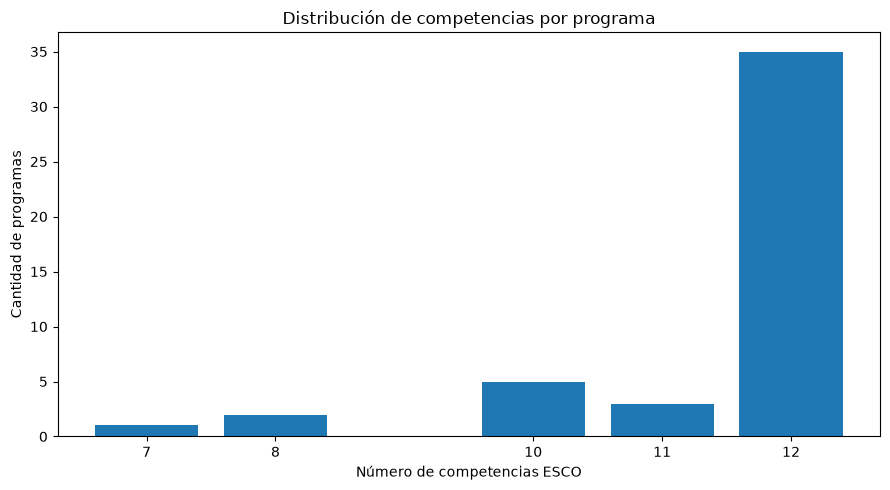

In [5]:
por_carrera = (
    competencias
    .groupby(["Universidad", "Carrera"])
    .size()
    .reset_index(name="N_Competencias")
)

print("Estadísticas descriptivas:")

display(por_carrera["N_Competencias"].describe())

# Distribución de frecuencias
distribucion = (
    por_carrera["N_Competencias"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))

plt.bar(
    distribucion.index,
    distribucion.values
)

plt.xlabel("Número de competencias ESCO")
plt.ylabel("Cantidad de programas")
plt.title("Distribución de competencias por programa")
plt.xticks(distribucion.index)

plt.tight_layout()
plt.show()

,Programas,Asignaciones_ESCO
Universidad,,
UNIVERSIDAD DE LA SERENA,11,123
IP INACAP,10,111
IP AIEP,6,70
UNIVERSIDAD CATOLICA DEL NORTE,6,71
IP DE CHILE,3,36
IP SANTO TOMAS,3,36
UNIVERSIDAD SANTO TOMAS,3,35
UNIVERSIDAD CENTRAL DE CHILE,2,20
UNIVERSIDAD DEL ALBA,2,24


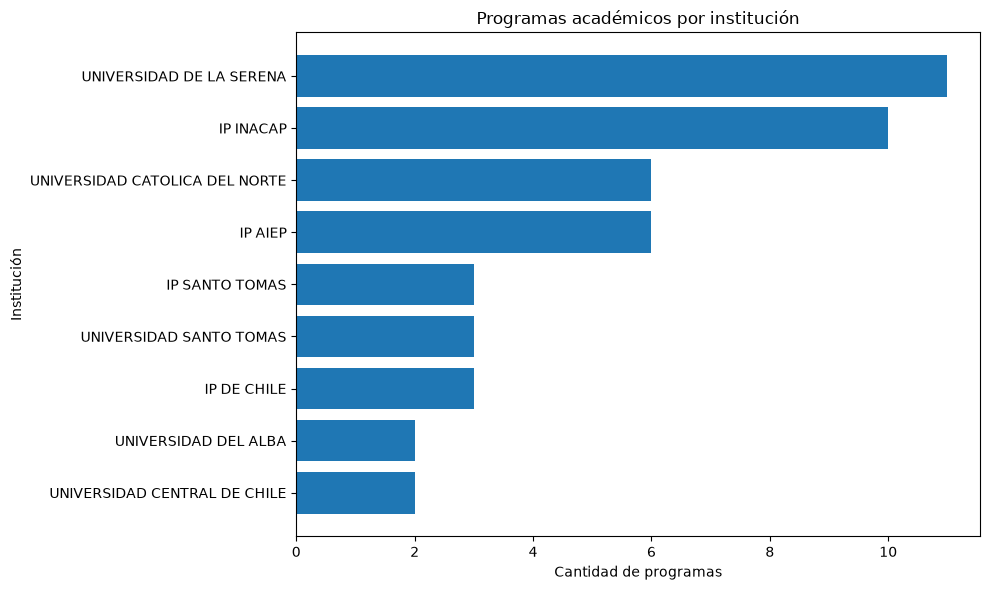

In [6]:
por_institucion = (
    df.groupby("Universidad")
    .size()
    .rename("Programas")
    .to_frame()
    .join(
        competencias.groupby("Universidad")
        .size()
        .rename("Asignaciones_ESCO")
    )
    .sort_values("Programas", ascending=False)
)

display(por_institucion)

# Gráfico
datos = por_institucion.sort_values("Programas")

plt.figure(figsize=(10, 6))

plt.barh(
    datos.index,
    datos["Programas"]
)

plt.xlabel("Cantidad de programas")
plt.ylabel("Institución")
plt.title("Programas académicos por institución")

plt.tight_layout()
plt.show()

,Competencia,N_Carreras,URI
110,gestionar proyectos de ingeniería,22,http://data.europa.eu/esco/skill/6a899482-8bcf...
174,utilizar sistemas de contabilidad,12,http://data.europa.eu/esco/skill/a0d79341-8398...
49,gestionar bases de datos,8,http://data.europa.eu/esco/skill/29fb0fb5-dfc4...
200,instalar un sistema operativo,8,http://data.europa.eu/esco/skill/c330db31-7fa9...
178,diseñar un sistema de información,8,http://data.europa.eu/esco/skill/a47d194d-0ffd...
161,aplicar gestión estratégica,8,http://data.europa.eu/esco/skill/953445c0-4770...
23,elaborar estrategias de marketing,8,http://data.europa.eu/esco/skill/13e2378e-0d10...
246,definir la arquitectura del software,8,http://data.europa.eu/esco/skill/f7e2eb04-3e50...
228,evaluar la viabilidad financiera,8,http://data.europa.eu/esco/skill/e95058a6-e139...
152,planificar operaciones mineras,7,http://data.europa.eu/esco/skill/8eecdac1-a79f...


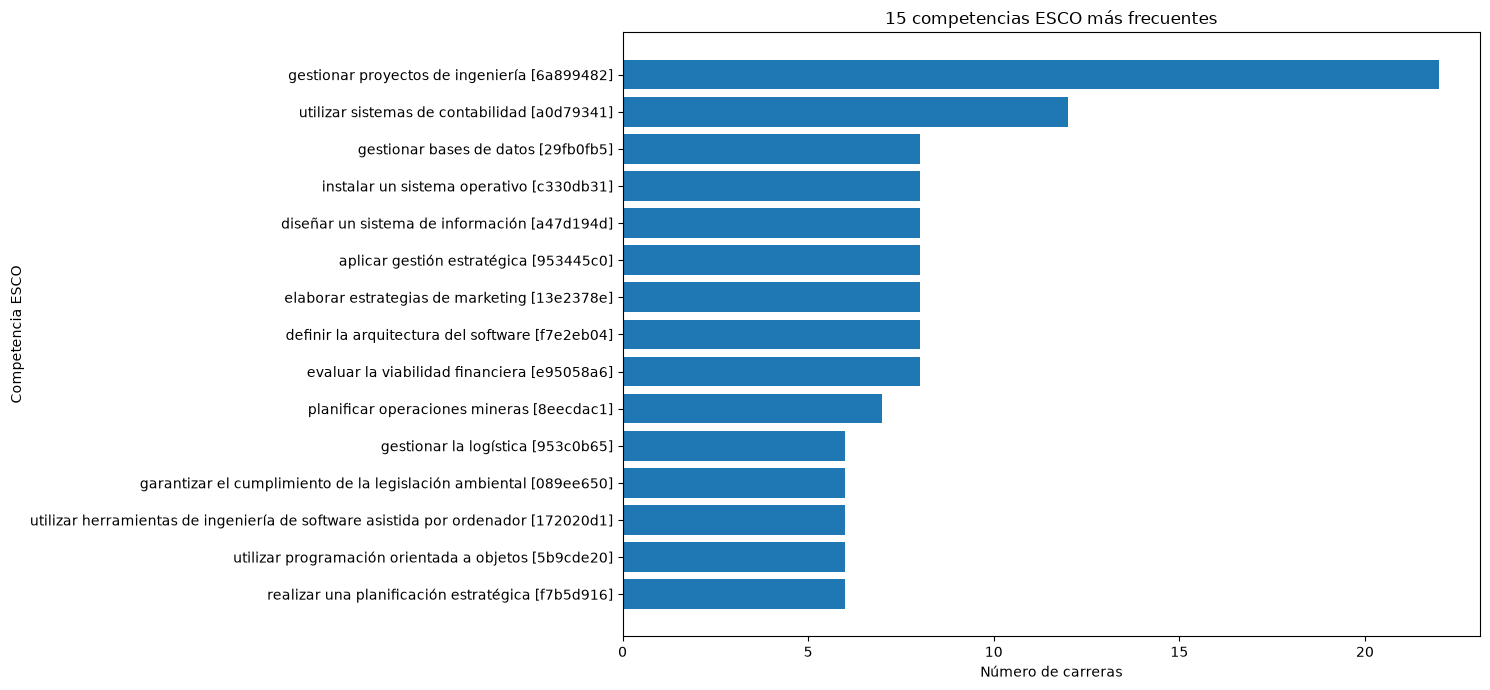

In [20]:
frecuencia = (
    competencias
    .drop_duplicates(
        subset=["Universidad", "Carrera", "URI"]
    )
    .groupby(["URI", "Competencia"])
    .size()
    .reset_index(name="N_Carreras")
    .sort_values("N_Carreras", ascending=False)
)

# Las 15 más frecuentes
top15 = frecuencia.head(15)

display(
    top15[["Competencia", "N_Carreras", "URI"]]
)

# Etiquetas para el gráfico
etiquetas = [
    f"{fila.Competencia} [{fila.URI.split('/')[-1][:8]}]"
    for fila in top15.itertuples()
]

plt.figure(figsize=(15, 7))

plt.barh(
    etiquetas[::-1],
    top15["N_Carreras"].values[::-1]
)

plt.xlabel("Número de carreras")
plt.ylabel("Competencia ESCO")
plt.title("15 competencias ESCO más frecuentes")

plt.tight_layout()
plt.show()

In [8]:
exclusivas = frecuencia[
    frecuencia["N_Carreras"] == 1
]

compartidas = frecuencia[
    frecuencia["N_Carreras"] > 1
]

print("Competencias presentes en una carrera:", len(exclusivas))

print("Competencias presentes en varias carreras:", len(compartidas))

print(
    "Porcentaje de competencias compartidas:",
    round(len(compartidas) / len(frecuencia) * 100, 2),
    "%"
)

Competencias presentes en una carrera: 153
Competencias presentes en varias carreras: 102
Porcentaje de competencias compartidas: 40.0 %


In [9]:

import pandas as pd
import matplotlib.pyplot as plt
import json
import unicodedata
import re
from itertools import combinations
from IPython.display import display

# Cargar archivo limpio
df = pd.read_csv(
    "Perfiles_Normalizados_ESCO_Limpio.csv",
    sep=";",
    encoding="utf-8-sig"
)

# Función para comparar nombres sin diferencias de
# mayúsculas, tildes o espacios
def normalizar(texto):
    texto = str(texto).strip().lower()
    texto = "".join(
        c for c in unicodedata.normalize("NFD", texto)
        if unicodedata.category(c) != "Mn"
    )
    return re.sub(r"\s+", " ", texto)

df["Carrera_clave"] = df["Carrera"].apply(normalizar)

# Carreras impartidas por más de una institución
conteo = (
    df.groupby("Carrera_clave")["Universidad"]
    .nunique()
)

claves_repetidas = conteo[conteo > 1].index

repetidas = (
    df[df["Carrera_clave"].isin(claves_repetidas)]
    .groupby("Carrera_clave")
    .agg(
        Carrera=("Carrera", "first"),
        Universidades=("Universidad", "nunique"),
        Instituciones=("Universidad", lambda x: " | ".join(sorted(x.unique())))
    )
    .reset_index(drop=True)
    .sort_values("Universidades", ascending=False)
)

print("Carreras con el mismo nombre:", len(repetidas))
display(repetidas)


Carreras con el mismo nombre: 8


,Carrera,Universidades,Instituciones
4,INGENIERIA EN ADMINISTRACION DE EMPRESAS,4,IP AIEP | IP DE CHILE | IP INACAP | UNIVERSIDA...
0,INGENIERIA CIVIL EN COMPUTACION E INFORMATICA,3,UNIVERSIDAD CATOLICA DEL NORTE | UNIVERSIDAD C...
2,INGENIERIA CIVIL INDUSTRIAL,3,UNIVERSIDAD CATOLICA DEL NORTE | UNIVERSIDAD D...
1,INGENIERIA CIVIL EN MINAS,3,UNIVERSIDAD CENTRAL DE CHILE | UNIVERSIDAD DEL...
3,INGENIERIA COMERCIAL,3,UNIVERSIDAD CATOLICA DEL NORTE | UNIVERSIDAD D...
5,INGENIERIA EN INFORMATICA,3,IP AIEP | IP INACAP | IP SANTO TOMAS
6,INGENIERIA EN MECANICA AUTOMOTRIZ Y AUTOTRONICA,2,IP AIEP | IP DE CHILE
7,INGENIERIA EN MINAS,2,IP AIEP | IP DE CHILE


In [10]:

# Preparar asignaturas
def preparar_asignaturas(texto):
    return {
        normalizar(asignatura)
        for asignatura in str(texto).split(",")
        if asignatura.strip()
    }

df["Asignaturas_set"] = df["Asignaturas"].apply(
    preparar_asignaturas
)

# Preparar URI de ESCO
df["ESCO_set"] = df["Competencias_ESCO_URI"].apply(
    lambda texto: set(json.loads(texto))
)

# Función de similitud Jaccard
def similitud_jaccard(conjunto_a, conjunto_b):
    union = conjunto_a | conjunto_b

    if not union:
        return float("nan")

    interseccion = conjunto_a & conjunto_b

    return 100 * len(interseccion) / len(union)

print("Datos preparados correctamente.")


Datos preparados correctamente.


In [11]:

resultados = []

for clave, grupo in df[
    df["Carrera_clave"].isin(claves_repetidas)
].groupby("Carrera_clave"):

    for (_, a), (_, b) in combinations(
        grupo.iterrows(), 2
    ):

        asignaturas_a = a["Asignaturas_set"]
        asignaturas_b = b["Asignaturas_set"]

        esco_a = a["ESCO_set"]
        esco_b = b["ESCO_set"]

        resultados.append({
            "Carrera": a["Carrera"],
            "Universidad A": a["Universidad"],
            "Universidad B": b["Universidad"],

            "Asignaturas A": len(asignaturas_a),
            "Asignaturas B": len(asignaturas_b),

            "Asignaturas compartidas": len(
                asignaturas_a & asignaturas_b
            ),

            "Similitud mallas (%)": round(
                similitud_jaccard(
                    asignaturas_a, asignaturas_b
                ), 2
            ),

            "ESCO compartidas": len(
                esco_a & esco_b
            ),

            "Similitud ESCO (%)": round(
                similitud_jaccard(esco_a, esco_b), 2
            )
        })

comparacion = pd.DataFrame(resultados)

display(
    comparacion.sort_values(
        ["Carrera", "Similitud mallas (%)"]
    )
)


,Carrera,Universidad A,Universidad B,Asignaturas A,Asignaturas B,Asignaturas compartidas,Similitud mallas (%),ESCO compartidas,Similitud ESCO (%)
1,INGENIERIA CIVIL EN COMPUTACION E INFORMATICA,UNIVERSIDAD DE LA SERENA,UNIVERSIDAD CATOLICA DEL NORTE,53,60,8,7.62,8,50.00
0,INGENIERIA CIVIL EN COMPUTACION E INFORMATICA,UNIVERSIDAD DE LA SERENA,UNIVERSIDAD CENTRAL DE CHILE,53,27,8,11.11,5,33.33
2,INGENIERIA CIVIL EN COMPUTACION E INFORMATICA,UNIVERSIDAD CENTRAL DE CHILE,UNIVERSIDAD CATOLICA DEL NORTE,27,60,11,14.47,5,33.33
4,INGENIERIA CIVIL EN MINAS,UNIVERSIDAD SANTO TOMAS,UNIVERSIDAD CENTRAL DE CHILE,66,35,2,2.02,6,33.33
3,INGENIERIA CIVIL EN MINAS,UNIVERSIDAD SANTO TOMAS,UNIVERSIDAD DEL ALBA,66,61,7,5.83,8,50.00
5,INGENIERIA CIVIL EN MINAS,UNIVERSIDAD DEL ALBA,UNIVERSIDAD CENTRAL DE CHILE,61,35,10,11.63,8,50.00
6,INGENIERIA CIVIL INDUSTRIAL,UNIVERSIDAD DEL ALBA,UNIVERSIDAD DE LA SERENA,61,61,5,4.27,2,9.09
8,INGENIERIA CIVIL INDUSTRIAL,UNIVERSIDAD DE LA SERENA,UNIVERSIDAD CATOLICA DEL NORTE,61,50,5,4.72,5,26.32
7,INGENIERIA CIVIL INDUSTRIAL,UNIVERSIDAD DEL ALBA,UNIVERSIDAD CATOLICA DEL NORTE,61,50,10,9.90,4,20.00
10,INGENIERIA COMERCIAL,UNIVERSIDAD SANTO TOMAS,UNIVERSIDAD CATOLICA DEL NORTE,59,53,4,3.70,4,20.00


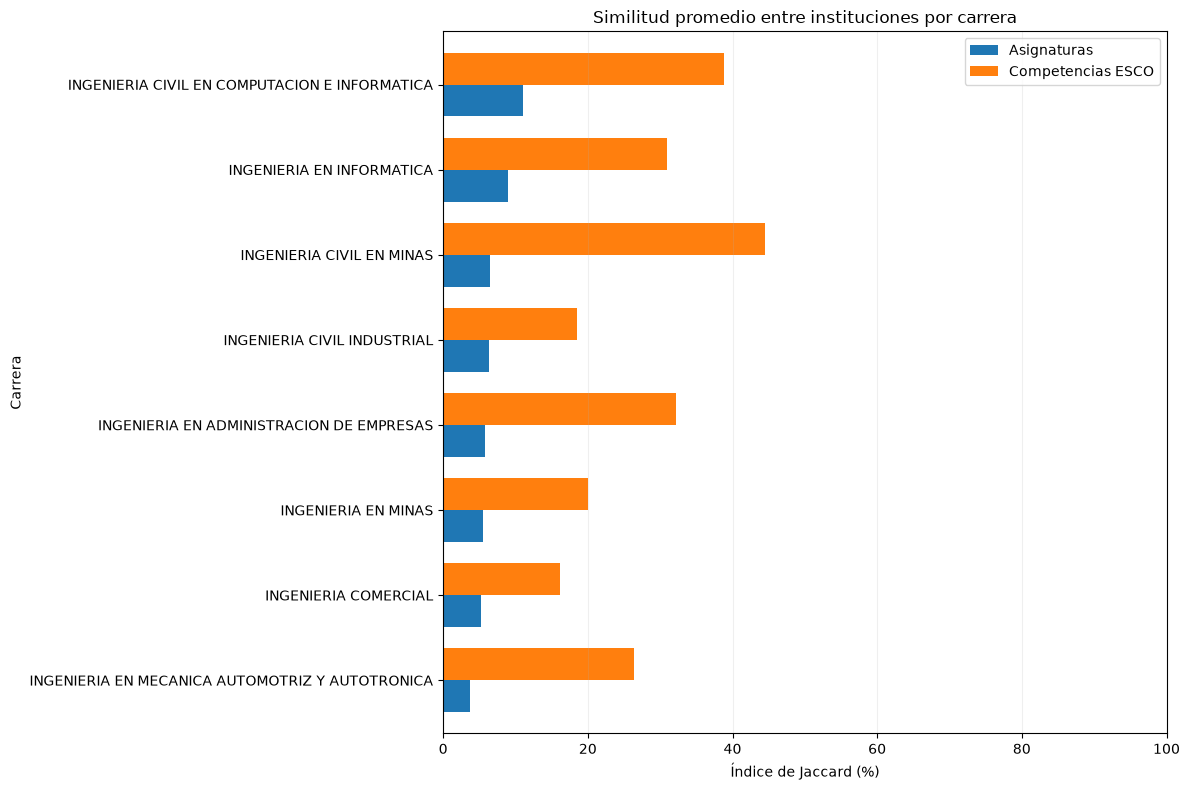

In [12]:

resumen = (
    comparacion
    .groupby("Carrera")[
        ["Similitud mallas (%)", "Similitud ESCO (%)"]
    ]
    .mean()
    .sort_values("Similitud mallas (%)")
)

ax = resumen.plot(
    kind="barh",
    figsize=(12, 8),
    width=0.75
)

plt.title(
    "Similitud promedio entre instituciones por carrera"
)
plt.xlabel("Índice de Jaccard (%)")
plt.ylabel("Carrera")

plt.xlim(0, 100)
plt.legend(
    ["Asignaturas", "Competencias ESCO"]
)
plt.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


In [15]:

# CAMBIAR AQUÍ LA CARRERA
carrera_elegida = "INGENIERIA CIVIL EN MINAS"

grupo = df[
    df["Carrera_clave"] == normalizar(carrera_elegida)
].copy()

if grupo["Universidad"].nunique() < 2:
    print("No hay suficientes universidades para comparar.")

else:
    print("CARRERA:", carrera_elegida)
    print("\nComparaciones entre universidades:")

    display(
        comparacion[
            comparacion["Carrera"].apply(normalizar)
            == normalizar(carrera_elegida)
        ]
    )

    # Asignaturas compartidas por TODAS las instituciones
    conjuntos = grupo["Asignaturas_set"].tolist()

    comunes = set.intersection(*conjuntos)

    print("\nASIGNATURAS COMPARTIDAS POR TODAS:")
    print("Cantidad:", len(comunes))

    # Recuperar los nombres originales de asignaturas
    nombres_originales = {}

    for texto in grupo["Asignaturas"]:
        for nombre in str(texto).split(","):
            if nombre.strip():
                nombres_originales.setdefault(
                    normalizar(nombre), nombre.strip()
                )

    display(pd.DataFrame({
        "Asignatura compartida": [
            nombres_originales[c] for c in sorted(comunes)
        ]
    }))

    # Asignaturas exclusivas de cada institución
    for _, fila in grupo.iterrows():

        universidad = fila["Universidad"]
        propias = fila["Asignaturas_set"]

        otras = set().union(*[
            f["Asignaturas_set"]
            for _, f in grupo.iterrows()
            if f["Universidad"] != universidad
        ])

        exclusivas = propias - otras

        print("\n", "=" * 45)
        print("UNIVERSIDAD:", universidad)
        print("Total de asignaturas:", len(propias))
        print("Asignaturas exclusivas:", len(exclusivas))

        display(pd.DataFrame({
            "Asignatura exclusiva": [
                nombres_originales[c]
                for c in sorted(exclusivas)
            ]
        }).head(20))


CARRERA: INGENIERIA CIVIL EN MINAS

Comparaciones entre universidades:


,Carrera,Universidad A,Universidad B,Asignaturas A,Asignaturas B,Asignaturas compartidas,Similitud mallas (%),ESCO compartidas,Similitud ESCO (%)
3,INGENIERIA CIVIL EN MINAS,UNIVERSIDAD SANTO TOMAS,UNIVERSIDAD DEL ALBA,66,61,7,5.83,8,50.00
4,INGENIERIA CIVIL EN MINAS,UNIVERSIDAD SANTO TOMAS,UNIVERSIDAD CENTRAL DE CHILE,66,35,2,2.02,6,33.33
5,INGENIERIA CIVIL EN MINAS,UNIVERSIDAD DEL ALBA,UNIVERSIDAD CENTRAL DE CHILE,61,35,10,11.63,8,50.00



ASIGNATURAS COMPARTIDAS POR TODAS:
Cantidad: 1


,Asignatura compartida
0,Geología General



UNIVERSIDAD: UNIVERSIDAD SANTO TOMAS
Total de asignaturas: 66
Asignaturas exclusivas: 58


,Asignatura exclusiva
0,Algoritmos y Programación
1,Cierre de Faenas Mineras
2,Ciudadanía y Sociedad
3,Diseño y Planificación Minera a Cielo Abierto
4,Diseño y Planificación Minera Subterránea
5,Economía Industrial
6,Economía Minera
7,Electivo Formación General I
8,Electivo Formación General II
9,Electivo Formación General III



UNIVERSIDAD: UNIVERSIDAD DEL ALBA
Total de asignaturas: 61
Asignaturas exclusivas: 45


,Asignatura exclusiva
0,Administración de Contratos Mineros
1,Álgebra II
2,Bases de Datos
3,Desarrollo Sostenible
4,Economía en Minería
5,Electivo de Especialidad I
6,Electivo de Especialidad II
7,Electromagnetismo
8,Formulación y Evaluación de Proyectos en Minería
9,Fundamentos de Ventilación de Minas



UNIVERSIDAD: UNIVERSIDAD CENTRAL DE CHILE
Total de asignaturas: 35
Asignaturas exclusivas: 24


,Asignatura exclusiva
0,Álgebra Lineal
1,Cálculo III
2,Diseño y Planificación Minera
3,Economía de Minerales
4,Evaluación de Yacimientos
5,Geología Estructural
6,Geomecánica Aplicada
7,Hidrometalurgia y Electrometalurgia
8,Introducción a la Ingeniería en Minas
9,Mecánica de Sólidos


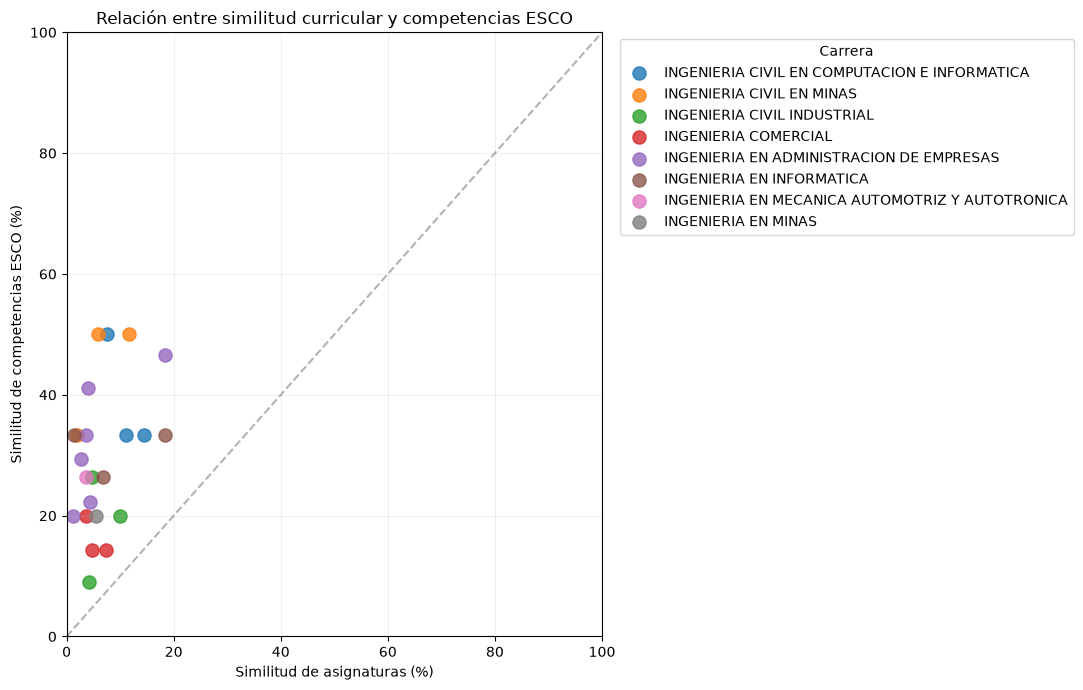

In [16]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

for carrera, grupo in comparacion.groupby("Carrera"):

    plt.scatter(
        grupo["Similitud mallas (%)"],
        grupo["Similitud ESCO (%)"],
        label=carrera,
        s=90,
        alpha=0.8
    )

# Línea donde ambas similitudes serían iguales
plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    color="gray",
    alpha=0.6
)

plt.xlabel("Similitud de asignaturas (%)")
plt.ylabel("Similitud de competencias ESCO (%)")

plt.title(
    "Relación entre similitud curricular y competencias ESCO"
)

plt.xlim(0, 100)
plt.ylim(0, 100)

plt.grid(alpha=0.2)

plt.legend(
    title="Carrera",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


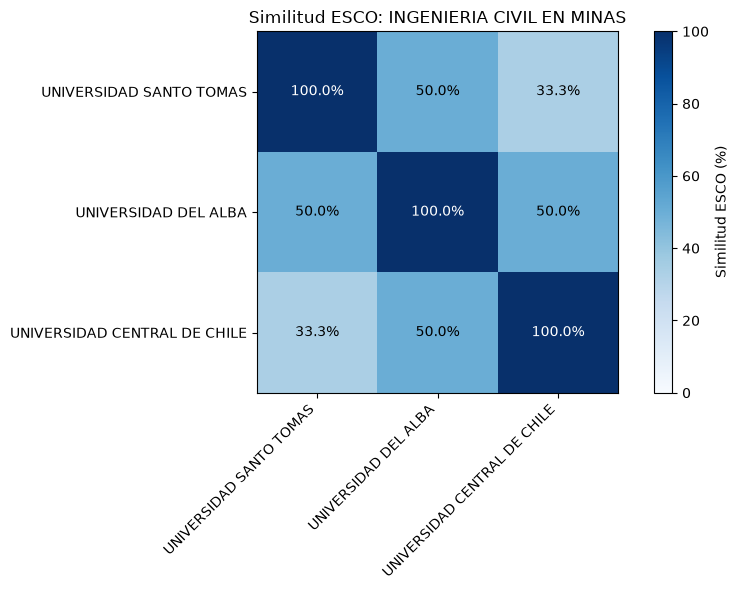

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# Seleccionar carrera
carrera = "INGENIERIA CIVIL EN MINAS"

grupo = df[
    df["Carrera_clave"] == normalizar(carrera)
].reset_index(drop=True)

universidades = grupo["Universidad"].tolist()
n = len(grupo)

matriz = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        matriz[i, j] = similitud_jaccard(
            grupo.loc[i, "ESCO_set"],
            grupo.loc[j, "ESCO_set"]
        )

fig, ax = plt.subplots(figsize=(9, 6))

im = ax.imshow(matriz, cmap="Blues", vmin=0, vmax=100)

ax.set_xticks(range(n))
ax.set_yticks(range(n))

ax.set_xticklabels(universidades, rotation=45, ha="right")
ax.set_yticklabels(universidades)

for i in range(n):
    for j in range(n):
        ax.text(
            j, i,
            f"{matriz[i, j]:.1f}%",
            ha="center",
            va="center",
            color="white" if matriz[i, j] > 60 else "black"
        )

plt.colorbar(im, label="Similitud ESCO (%)")
plt.title(f"Similitud ESCO: {carrera}")

plt.tight_layout()
plt.show()

In [18]:

import pandas as pd
import json
import unicodedata
import re
from IPython.display import display

# Cargar el archivo limpio
df = pd.read_csv(
    "Perfiles_Normalizados_ESCO_Limpio.csv",
    sep=";",
    encoding="utf-8-sig"
)

def normalizar(texto):
    texto = str(texto).strip().lower()
    texto = "".join(
        c for c in unicodedata.normalize("NFD", texto)
        if unicodedata.category(c) != "Mn"
    )
    return re.sub(r"\s+", " ", texto)

# Crear diccionarios de ramos y competencias
df["Carrera_clave"] = df["Carrera"].apply(normalizar)

df["Ramos_mapa"] = df["Asignaturas"].apply(
    lambda texto: {
        normalizar(ramo): ramo.strip()
        for ramo in str(texto).split(",")
        if ramo.strip()
    }
)

df["ESCO_mapa"] = df["Competencias_ESCO_Detalle"].apply(
    lambda texto: {
        item["uri"]: item["etiqueta"]
        for item in json.loads(texto)
    }
)

# ==========================================
# SELECCIONAR CARRERA
# ==========================================
carrera_elegida = "INGENIERIA CIVIL EN MINAS"

grupo = df[
    df["Carrera_clave"] == normalizar(carrera_elegida)
].copy()

if grupo["Universidad"].nunique() < 2:
    print("La carrera no aparece en dos o más universidades.")

else:
    print("CARRERA:", carrera_elegida)
    print("\nUniversidades:")
    for universidad in grupo["Universidad"]:
        print("-", universidad)

    # Intersección de ramos entre todas
    ramos_comunes = set.intersection(
        *(set(m) for m in grupo["Ramos_mapa"])
    )

    # Intersección de URI ESCO entre todas
    esco_comunes = set.intersection(
        *(set(m) for m in grupo["ESCO_mapa"])
    )

    referencia = grupo.iloc[0]

    tabla_ramos = pd.DataFrame({
        "Ramos compartidos": sorted(
            referencia["Ramos_mapa"][r]
            for r in ramos_comunes
        )
    })

    tabla_esco = pd.DataFrame([
        {
            "Competencia ESCO": referencia["ESCO_mapa"][uri],
            "URI": uri
        }
        for uri in sorted(esco_comunes)
    ]).sort_values(
        "Competencia ESCO"
    ) if esco_comunes else pd.DataFrame(
        columns=["Competencia ESCO", "URI"]
    )

    print("\nRAMOS COMPARTIDOS POR TODAS:")
    print("Cantidad:", len(ramos_comunes))
    display(tabla_ramos)

    print("\nCOMPETENCIAS ESCO COMPARTIDAS POR TODAS:")
    print("Cantidad:", len(esco_comunes))
    display(tabla_esco)


CARRERA: INGENIERIA CIVIL EN MINAS

Universidades:
- UNIVERSIDAD SANTO TOMAS
- UNIVERSIDAD DEL ALBA
- UNIVERSIDAD CENTRAL DE CHILE

RAMOS COMPARTIDOS POR TODAS:
Cantidad: 1


,Ramos compartidos
0,Geología General



COMPETENCIAS ESCO COMPARTIDAS POR TODAS:
Cantidad: 6


,Competencia ESCO,URI
5,desarrollar modelos de yacimientos mineros,http://data.europa.eu/esco/skill/f760d2c9-e7ef...
1,desarrollar programas de rehabilitación de minas,http://data.europa.eu/esco/skill/4a2d006d-8349...
0,diseñar infraestructuras para explotaciones a ...,http://data.europa.eu/esco/skill/28eb4689-3ba4...
3,evaluar proyectos de desarrollo minero,http://data.europa.eu/esco/skill/a1d24f87-230e...
2,planificar operaciones mineras,http://data.europa.eu/esco/skill/8eecdac1-a79f...
4,utilizar software de programación minera,http://data.europa.eu/esco/skill/a4ec696c-ac73...


In [19]:

from itertools import combinations

for (_, a), (_, b) in combinations(grupo.iterrows(), 2):

    if a["Universidad"] == b["Universidad"]:
        continue

    ramos = (
        set(a["Ramos_mapa"])
        & set(b["Ramos_mapa"])
    )

    competencias_esco = (
        set(a["ESCO_mapa"])
        & set(b["ESCO_mapa"])
    )

    print("\n" + "=" * 65)
    print(a["Universidad"])
    print("VS")
    print(b["Universidad"])
    print("=" * 65)

    print(f"\nRAMOS COMPARTIDOS: {len(ramos)}")

    display(pd.DataFrame({
        "Ramo compartido": sorted(
            a["Ramos_mapa"][r] for r in ramos
        )
    }))

    print(
        f"\nCOMPETENCIAS ESCO COMPARTIDAS: "
        f"{len(competencias_esco)}"
    )

    tabla = pd.DataFrame([
        {
            "Competencia ESCO": a["ESCO_mapa"][uri],
            "URI": uri
        }
        for uri in competencias_esco
    ])

    if not tabla.empty:
        tabla = tabla.sort_values("Competencia ESCO")

    display(tabla)



UNIVERSIDAD SANTO TOMAS
VS
UNIVERSIDAD DEL ALBA

RAMOS COMPARTIDOS: 7


,Ramo compartido
0,Administración Moderna
1,Carguío y Transporte
2,Geología General
3,Procesos Metalúrgicos
4,Proyecto de Título
5,Práctica Profesional
6,Seminario de Título



COMPETENCIAS ESCO COMPARTIDAS: 8


,Competencia ESCO,URI
3,desarrollar estrategias en materia de salud y ...,http://data.europa.eu/esco/skill/15725b82-9608...
0,desarrollar modelos de yacimientos mineros,http://data.europa.eu/esco/skill/f760d2c9-e7ef...
6,desarrollar programas de rehabilitación de minas,http://data.europa.eu/esco/skill/4a2d006d-8349...
7,diseñar infraestructuras para explotaciones a ...,http://data.europa.eu/esco/skill/28eb4689-3ba4...
4,evaluar proyectos de desarrollo minero,http://data.europa.eu/esco/skill/a1d24f87-230e...
1,manejar perforadoras para minería,http://data.europa.eu/esco/skill/0557b66b-3ac5...
2,planificar operaciones mineras,http://data.europa.eu/esco/skill/8eecdac1-a79f...
5,utilizar software de programación minera,http://data.europa.eu/esco/skill/a4ec696c-ac73...



UNIVERSIDAD SANTO TOMAS
VS
UNIVERSIDAD CENTRAL DE CHILE

RAMOS COMPARTIDOS: 2


,Ramo compartido
0,Geología General
1,Legislación y Seguridad Minera


... (2 outputs left out)


UNIVERSIDAD DEL ALBA
VS
UNIVERSIDAD CENTRAL DE CHILE

RAMOS COMPARTIDOS: 10


,Ramo compartido
0,Cálculo I
1,Cálculo II
2,Ecuaciones Diferenciales
3,Estadística y Probabilidades
4,Física I
5,Física II
6,Geología General
7,Mecánica de Fluidos
8,Termodinámica
9,Álgebra I



COMPETENCIAS ESCO COMPARTIDAS: 8


,Competencia ESCO,URI
0,desarrollar modelos de yacimientos mineros,http://data.europa.eu/esco/skill/f760d2c9-e7ef...
5,desarrollar programas de rehabilitación de minas,http://data.europa.eu/esco/skill/4a2d006d-8349...
6,diseñar infraestructuras para explotaciones a ...,http://data.europa.eu/esco/skill/28eb4689-3ba4...
3,evaluar proyectos de desarrollo minero,http://data.europa.eu/esco/skill/a1d24f87-230e...
1,gestionar sistemas de ventilación de minas,http://data.europa.eu/esco/skill/6caa915b-b80d...
7,implementar procesos minerales,http://data.europa.eu/esco/skill/e13dc8bb-c81f...
2,planificar operaciones mineras,http://data.europa.eu/esco/skill/8eecdac1-a79f...
4,utilizar software de programación minera,http://data.europa.eu/esco/skill/a4ec696c-ac73...


In [21]:
# Mostrar textos completos sin truncar
pd.set_option("display.max_colwidth", None)

# Las 15 competencias más frecuentes
top15 = frecuencia.head(15)

display(
    top15[["Competencia", "N_Carreras", "URI"]]
    .style.set_properties(
        subset=["URI"],
        **{
            "white-space": "normal",
            "overflow-wrap": "anywhere",
            "max-width": "450px",
            "text-align": "left"
        }
    )
)

,Competencia,N_Carreras,URI
110,gestionar proyectos de ingeniería,22,http://data.europa.eu/esco/skill/6a899482-8bcf-40ca-ae67-579a1cc467ab
174,utilizar sistemas de contabilidad,12,http://data.europa.eu/esco/skill/a0d79341-8398-4019-ad1b-27888ec35aaa
49,gestionar bases de datos,8,http://data.europa.eu/esco/skill/29fb0fb5-dfc4-4098-ac9b-3a712000f48f
200,instalar un sistema operativo,8,http://data.europa.eu/esco/skill/c330db31-7fa9-4a8c-8ad6-baa957bcfed1
178,diseñar un sistema de información,8,http://data.europa.eu/esco/skill/a47d194d-0ffd-4aaa-b695-fbbe0255000e
161,aplicar gestión estratégica,8,http://data.europa.eu/esco/skill/953445c0-4770-4be0-91cf-270a64c0e297
23,elaborar estrategias de marketing,8,http://data.europa.eu/esco/skill/13e2378e-0d10-450d-843a-b3592575826e
246,definir la arquitectura del software,8,http://data.europa.eu/esco/skill/f7e2eb04-3e50-4561-bce1-7e51a1fec308
228,evaluar la viabilidad financiera,8,http://data.europa.eu/esco/skill/e95058a6-e139-42e7-a470-72038a606649
152,planificar operaciones mineras,7,http://data.europa.eu/esco/skill/8eecdac1-a79f-4d4b-b7b6-1d9bc80b6265


In [22]:
%pip install ipywidgets

   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 2.2/2.2 MB 35.5 MB/s  0:00:00

   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   ---------------------------------------- 3/3 [ipywidgets]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:


import pandas as pd
import json
from IPython.display import display

# ==========================================
# 1. CARGAR DATOS
# ==========================================

df = pd.read_csv(
    "Perfiles_Normalizados_ESCO_Limpio.csv",
    sep=";",
    encoding="utf-8-sig"
)

pd.set_option("display.max_colwidth", None)

universidades = sorted(df["Universidad"].dropna().unique())

# ==========================================
# 2. EXPLORADOR INTERACTIVO
# ==========================================

while True:

    print("\n" + "=" * 65)
    print("SELECCIONAR UNIVERSIDAD")
    print("=" * 65)

    for i, universidad in enumerate(universidades, 1):
        print(f"{i}. {universidad}")

    print("0. SALIR")

    opcion = input("\nNúmero de universidad: ").strip()

    if opcion == "0":
        print("Explorador finalizado.")
        break

    if not opcion.isdigit() or not 1 <= int(opcion) <= len(universidades):
        print("Número de universidad no válido.")
        continue

    universidad = universidades[int(opcion) - 1]

    carreras = (
        df[df["Universidad"] == universidad]
        .reset_index(drop=True)
    )

    while True:

        print("\n" + "=" * 65)
        print("UNIVERSIDAD:", universidad)
        print("=" * 65)

        print("\nCARRERAS DISPONIBLES:")

        for i, carrera in enumerate(carreras["Carrera"], 1):
            print(f"{i}. {carrera}")

        print("\n0. CAMBIAR UNIVERSIDAD")

        opcion_carrera = input(
            "\nNúmero de carrera: "
        ).strip()

        if opcion_carrera == "0":
            break

        if (
            not opcion_carrera.isdigit()
            or not 1 <= int(opcion_carrera) <= len(carreras)
        ):
            print("Número de carrera no válido.")
            continue

        fila = carreras.iloc[int(opcion_carrera) - 1]

        print("\n" + "=" * 65)
        print("CARRERA:", fila["Carrera"])
        print("UNIVERSIDAD:", universidad)
        print("=" * 65)

        # Leer competencias ESCO
        try:
            detalles = json.loads(
                fila["Competencias_ESCO_Detalle"]
            )
        except (TypeError, json.JSONDecodeError):
            print("Error al leer las competencias ESCO.")
            continue

        # Construir tabla
        registros = []

        for i, item in enumerate(detalles, 1):
            registros.append({
                "N°": i,
                "Evidencia original": item.get("evidencia", ""),
                "Competencia ESCO": item.get("etiqueta", "")
            })

        tabla = pd.DataFrame(registros)

        print("\nCOMPETENCIAS NORMALIZADAS:")
        print("Total:", len(tabla))

        display(
            tabla.style.set_properties(
                **{
                    "white-space": "normal",
                    "overflow-wrap": "anywhere",
                    "text-align": "left"
                }
            )
        )

        print("\nPuedes seleccionar otra carrera.")



SELECCIONAR UNIVERSIDAD
1. IP AIEP
2. IP DE CHILE
3. IP INACAP
4. IP SANTO TOMAS
5. UNIVERSIDAD CATOLICA DEL NORTE
6. UNIVERSIDAD CENTRAL DE CHILE
7. UNIVERSIDAD DE LA SERENA
8. UNIVERSIDAD DEL ALBA
9. UNIVERSIDAD SANTO TOMAS
0. SALIR



Número de universidad:  5



UNIVERSIDAD: UNIVERSIDAD CATOLICA DEL NORTE

CARRERAS DISPONIBLES:
1. INGENIERIA CIVIL EN COMPUTACION E INFORMATICA
2. INGENIERIA CIVIL INDUSTRIAL
3. INGENIERIA COMERCIAL
4. INGENIERIA EN INFORMACION Y CONTROL DE GESTION
5. INGENIERIA EN TECNOLOGIAS DE INFORMACION
6. INGENIERIA EN PREVENCION DE RIESGOS Y MEDIOAMBIENTE

0. CAMBIAR UNIVERSIDAD



Número de carrera:  4



CARRERA: INGENIERIA EN INFORMACION Y CONTROL DE GESTION
UNIVERSIDAD: UNIVERSIDAD CATOLICA DEL NORTE

COMPETENCIAS NORMALIZADAS:
Total: 12


,N°,Evidencia original,Competencia ESCO
0,1,Gestión Estratégica,aplicar gestión estratégica
1,2,Base de Datos,gestionar bases de datos
2,3,Gestión de SIA y Procesos,gestionar sistemas administrativos
3,4,Método y Herramientas de Calidad y Riesgo,implementar sistemas de gestión de calidad
4,5,Contabilidad y Negocios,utilizar sistemas de contabilidad
5,6,Base de Datos,diseñar esquema de base de datos
6,7,Base de Datos,manejar sistema de gestión de bases de datos relacionales
7,8,Logística,gestionar la logística
8,9,Estadística I,aplicar métodos de análisis estadísticos
9,10,Desarrollo de SIA,analizar sistemas de información



Puedes seleccionar otra carrera.

UNIVERSIDAD: UNIVERSIDAD CATOLICA DEL NORTE

CARRERAS DISPONIBLES:
1. INGENIERIA CIVIL EN COMPUTACION E INFORMATICA
2. INGENIERIA CIVIL INDUSTRIAL
3. INGENIERIA COMERCIAL
4. INGENIERIA EN INFORMACION Y CONTROL DE GESTION
5. INGENIERIA EN TECNOLOGIAS DE INFORMACION
6. INGENIERIA EN PREVENCION DE RIESGOS Y MEDIOAMBIENTE

0. CAMBIAR UNIVERSIDAD



Número de carrera:  0



SELECCIONAR UNIVERSIDAD
1. IP AIEP
2. IP DE CHILE
3. IP INACAP
4. IP SANTO TOMAS
5. UNIVERSIDAD CATOLICA DEL NORTE
6. UNIVERSIDAD CENTRAL DE CHILE
7. UNIVERSIDAD DE LA SERENA
8. UNIVERSIDAD DEL ALBA
9. UNIVERSIDAD SANTO TOMAS
0. SALIR



Número de universidad:  0


Explorador finalizado.


In [ ]:
-